## PART-A

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.datasets import cifar10
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [2]:
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1616s 9us/step


In [4]:
X_train_small = []
y_train_small = []

for class_id in range(10):
    class_indices = np.where(y_train.flatten() == class_id)[0][:50]
    X_train_small.extend(X_train[class_indices])
    y_train_small.extend(y_train[class_indices])

X_train_small = np.array(X_train_small)
y_train_small = np.array(y_train_small)

X_train_small, X_val, y_train_small, y_val = train_test_split(
    X_train_small,
    y_train_small,
    test_size=100,
    random_state=SEED,
    stratify=y_train_small
)

print("Training images:", X_train_small.shape)
print("Validation images:", X_val.shape)

Training images: (400, 32, 32, 3)
Validation images: (100, 32, 32, 3)


In [6]:
X_train_small = X_train_small.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test_clean = X_test.astype("float32") / 255.0

In [7]:
def inception_module(x, filters):
    branch1 = layers.Conv2D(filters, 1, padding="same", activation="relu")(x)

    branch3 = layers.Conv2D(filters, 1, padding="same", activation="relu")(x)
    branch3 = layers.Conv2D(filters, 3, padding="same", activation="relu")(branch3)

    branch5 = layers.Conv2D(filters, 1, padding="same", activation="relu")(x)
    branch5 = layers.Conv2D(filters, 5, padding="same", activation="relu")(branch5)

    return layers.Concatenate()([branch1, branch3, branch5])

In [8]:
def build_baseline_model():
    inputs = layers.Input(shape=(32, 32, 3))

    x = layers.Conv2D(16, 3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D(2)(x)

    x = inception_module(x, 8)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


baseline_model = build_baseline_model()
baseline_model.summary()

I0000 00:00:1791702191.227066      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791702191.234957      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 16,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16, 8) │        136 │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16, 8) │        136 │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16, 8) │        136 │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16, 8) │        584 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16, 8) │      1,608 │ conv2d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_1[0][0],   │
│ (Concatenate)       │ 24)               │            │ conv2d_3[0][0],   │
│                     │                   │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 8, 8, 24)  │          0 │ concatenate[0][0] │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 8, 8, 32)  │      6,944 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ conv2d_6[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      2,112 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │        650 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,754 (49.82 KB)

 Trainable params: 12,754 (49.82 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history_baseline = baseline_model.fit(
    X_train_small,
    y_train_small,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
 1/13 ━━━━━━━━━━━━━━━━━━━━ 1:19 7s/step - accuracy: 0.2188 - loss: 2.3025

I0000 00:00:1791702233.204154     144 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 345ms/step - accuracy: 0.0975 - loss: 2.3033 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1000 - loss: 2.3028 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0875 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 

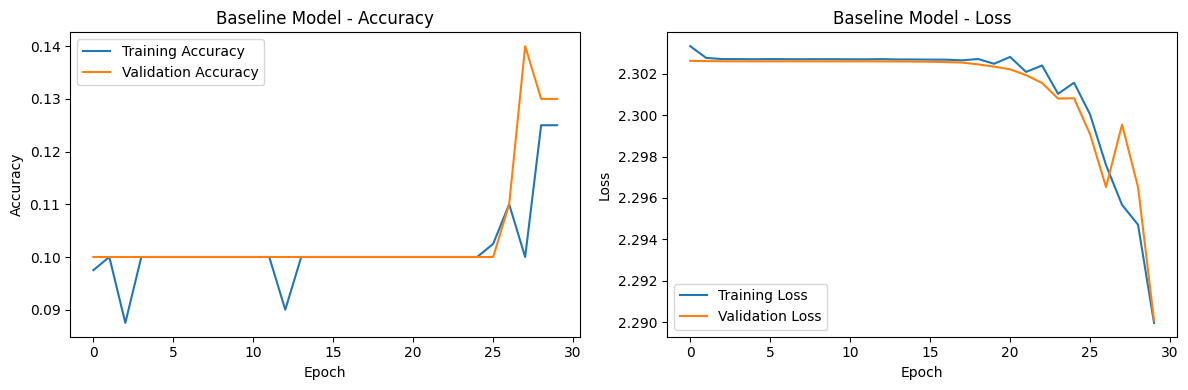

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_baseline.history["accuracy"], label="Training Accuracy")
plt.plot(history_baseline.history["val_accuracy"], label="Validation Accuracy")
plt.title("Baseline Model - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_baseline.history["loss"], label="Training Loss")
plt.plot(history_baseline.history["val_loss"], label="Validation Loss")
plt.title("Baseline Model - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
train_loss, train_accuracy = baseline_model.evaluate(
    X_train_small, y_train_small, verbose=0
)

val_loss, val_accuracy = baseline_model.evaluate(
    X_val, y_val, verbose=0
)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Training Accuracy: 17.25%
Validation Accuracy: 13.00%


In [12]:
clean_test_loss, clean_test_accuracy = baseline_model.evaluate(
    X_test_clean, y_test, verbose=1
)

print(f"Clean Test Accuracy: {clean_test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1000 - loss: 2.3825
Clean Test Accuracy: 10.00%


In [17]:
import tensorflow as tf
import numpy as np
from scipy.ndimage import rotate

rng = np.random.default_rng(SEED)

def corrupt_image(image):
    image = rotate(
        image,
        angle=rng.uniform(-25, 25),
        axes=(0, 1),
        reshape=False,
        mode="nearest"
    )

    image = image * rng.uniform(0.7, 1.3) + rng.uniform(-0.15, 0.15)
    image = np.clip(image, 0.0, 1.0)

    h, w, _ = image.shape
    cut_h, cut_w = int(h * 0.5), int(w * 0.5)
    top = rng.integers(0, h - cut_h + 1)
    left = rng.integers(0, w - cut_w + 1)
    image[top:top + cut_h, left:left + cut_w, :] = 0.0

    return image.astype("float32")

X_test_shifted_proxy = np.stack([
    corrupt_image(image) for image in X_test_clean
])

print("Shifted-test proxy shape:", X_test_shifted_proxy.shape)

Shifted-test proxy shape: (10000, 32, 32, 3)


In [18]:
shifted_test_loss, shifted_test_accuracy = baseline_model.evaluate(
    X_test_shifted_proxy, y_test, verbose=1
)

print(f"Shifted Test Proxy Accuracy: {shifted_test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1000 - loss: 2.3443
Shifted Test Proxy Accuracy: 10.00%


**Summary**
The baseline model shows poor generalization, with low training, validation, and clean-test accuracy. Its shifted-test proxy accuracy is also 10%, indicating that the model has not learned features that generalize well to unseen images. The limited training data of 400 images may contribute to underfitting, while the unstable learning curves indicate that the model is not learning effectively. The shifted-test result is based on a locally generated proxy because the teacher's original shifted-test dataset was not provided.

## PART-B

In [19]:
data_augmentation = models.Sequential([
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(25 / 360),
    layers.RandomFlip("horizontal"),
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.3)
])

In [20]:
def build_augmented_model():
    inputs = layers.Input(shape=(32, 32, 3))

    x = data_augmentation(inputs)
    x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)

    x = inception_module(x, 8)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


augmented_model = build_augmented_model()

In [21]:
history_augmented = augmented_model.fit(
    X_train_small,
    y_train_small,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.0875 - loss: 2.4003 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.0775 - loss: 2.3156 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1100 - loss: 2.3115 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0950 - loss: 2.3181 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0900 - loss: 2.3075 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0900 - loss: 2.3153 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0900 - loss: 2.3098 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0925 - loss: 2.3078 - val_accuracy: 0.1000 - v

In [22]:
aug_clean_loss, aug_clean_accuracy = augmented_model.evaluate(
    X_test_clean, y_test, verbose=1
)

aug_shifted_loss, aug_shifted_accuracy = augmented_model.evaluate(
    X_test_shifted_proxy, y_test, verbose=1
)

print(f"Augmented Model - Clean Test Accuracy: {aug_clean_accuracy * 100:.2f}%")
print(f"Augmented Model - Shifted Test Proxy Accuracy: {aug_shifted_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1000 - loss: 2.3023
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1000 - loss: 2.3024
Augmented Model - Clean Test Accuracy: 10.00%
Augmented Model - Shifted Test Proxy Accuracy: 10.00%


## PART-C

The augmented model is still at 10% accuracy on both test sets, so its results are not reliable yet. We should continue with the assignment's regularization experiment, but keep these results as they are rather than presenting them as successful.

In [23]:
def build_regularized_model():
    inputs = layers.Input(shape=(32, 32, 3))

    x = layers.Conv2D(
        16, 3, padding="same", activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = inception_module(x, 8)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(
        32, 3, padding="same", activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    )(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


regularized_model = build_regularized_model()

In [24]:
history_regularized = regularized_model.fit(
    X_train_small,
    y_train_small,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 397ms/step - accuracy: 0.0925 - loss: 2.3215 - val_accuracy: 0.1000 - val_loss: 2.3329
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1200 - loss: 2.2857 - val_accuracy: 0.1000 - val_loss: 2.3314
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1650 - loss: 2.2557 - val_accuracy: 0.1000 - val_loss: 2.3305
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1875 - loss: 2.2039 - val_accuracy: 0.1000 - val_loss: 2.3298
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1950 - loss: 2.1745 - val_accuracy: 0.1000 - val_loss: 2.3313
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.2050 - loss: 2.1451 - val_accuracy: 0.1000 - val_loss: 2.3314
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.2050 - loss: 2.1285 - val_accuracy: 0.1000 - val_loss: 2.3345
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1950 - loss: 2.0812 - val_accuracy: 0.1000 -

In [25]:
reg_clean_loss, reg_clean_accuracy = regularized_model.evaluate(
    X_test_clean, y_test, verbose=1
)

reg_shifted_loss, reg_shifted_accuracy = regularized_model.evaluate(
    X_test_shifted_proxy, y_test, verbose=1
)

print(f"Regularized Model - Clean Test Accuracy: {reg_clean_accuracy * 100:.2f}%")
print(f"Regularized Model - Shifted Test Proxy Accuracy: {reg_shifted_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.1815 - loss: 19.2900
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1274 - loss: 29.2442
Regularized Model - Clean Test Accuracy: 18.15%
Regularized Model - Shifted Test Proxy Accuracy: 12.74%


## PART-D

In [26]:
model_comparison = {
    "Baseline (No Augmentation)": [
        clean_test_accuracy * 100,
        shifted_test_accuracy * 100
    ],
    "Augmentation": [
        aug_clean_accuracy * 100,
        aug_shifted_accuracy * 100
    ],
    "Regularization": [
        reg_clean_accuracy * 100,
        reg_shifted_accuracy * 100
    ]
}

print(f"{'Model':<30}{'Clean Test (%)':<20}{'Shifted Proxy (%)'}")

for model_name, scores in model_comparison.items():
    print(f"{model_name:<30}{scores[0]:<20.2f}{scores[1]:.2f}")

Model                         Clean Test (%)      Shifted Proxy (%)
Baseline (No Augmentation)    10.00               10.00
Augmentation                  10.00               10.00
Regularization                18.15               12.74


In [31]:
geometric_augmentation = models.Sequential([
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(25 / 360),
    layers.RandomFlip("horizontal")
])

def build_geometric_model():
    inputs = layers.Input(shape=(32, 32, 3))

    x = geometric_augmentation(inputs)
    x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = inception_module(x, 8)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

geometric_model = build_geometric_model()

history_geometric = geometric_model.fit(
    X_train_small,
    y_train_small,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.0750 - loss: 2.3031 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0825 - loss: 2.3027 - val_accuracy: 0.1000 - v

In [32]:
geo_clean_loss, geo_clean_accuracy = geometric_model.evaluate(
    X_test_clean, y_test, verbose=1
)

geo_shifted_loss, geo_shifted_accuracy = geometric_model.evaluate(
    X_test_shifted_proxy, y_test, verbose=1
)

print(f"Geometric Only - Clean Test Accuracy: {geo_clean_accuracy * 100:.2f}%")
print(f"Geometric Only - Shifted Test Proxy Accuracy: {geo_shifted_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1000 - loss: 2.3032
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1000 - loss: 2.3031
Geometric Only - Clean Test Accuracy: 10.00%
Geometric Only - Shifted Test Proxy Accuracy: 10.00%


In [33]:
photometric_augmentation = models.Sequential([
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.3)
])

def build_photometric_model():
    inputs = layers.Input(shape=(32, 32, 3))

    x = photometric_augmentation(inputs)
    x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = inception_module(x, 8)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

photometric_model = build_photometric_model()

history_photometric = photometric_model.fit(
    X_train_small,
    y_train_small,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 327ms/step - accuracy: 0.0825 - loss: 2.4236 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1125 - loss: 2.3224 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0650 - loss: 2.3255 - val_accuracy: 0.1000 - val_loss: 2.3027
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0900 - loss: 2.3236 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0775 - loss: 2.3059 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1000 - loss: 2.3123 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1050 - loss: 2.3031 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1100 - loss: 2.3184 - val_accuracy: 0.1000 - 

In [34]:
photo_clean_loss, photo_clean_accuracy = photometric_model.evaluate(
    X_test_clean, y_test, verbose=1
)

photo_shifted_loss, photo_shifted_accuracy = photometric_model.evaluate(
    X_test_shifted_proxy, y_test, verbose=1
)

print(f"Photometric Only - Clean Test Accuracy: {photo_clean_accuracy * 100:.2f}%")
print(f"Photometric Only - Shifted Test Proxy Accuracy: {photo_shifted_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1032 - loss: 2.3027
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1000 - loss: 2.3027
Photometric Only - Clean Test Accuracy: 10.32%
Photometric Only - Shifted Test Proxy Accuracy: 10.00%


In [35]:
combined_augmentation = models.Sequential([
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(25 / 360),
    layers.RandomFlip("horizontal"),
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.3)
])

def build_combined_model():
    inputs = layers.Input(shape=(32, 32, 3))

    x = combined_augmentation(inputs)
    x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = inception_module(x, 8)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

combined_model = build_combined_model()

history_combined = combined_model.fit(
    X_train_small,
    y_train_small,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.0800 - loss: 2.5301 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1175 - loss: 2.3037 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0950 - loss: 2.3058 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1075 - loss: 2.3037 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0875 - loss: 2.3023 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1150 - loss: 2.3032 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1025 - loss: 2.3033 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1025 - loss: 2.3037 - val_accuracy: 0.1000 - v

In [36]:
combined_clean_loss, combined_clean_accuracy = combined_model.evaluate(
    X_test_clean, y_test, verbose=1
)

combined_shifted_loss, combined_shifted_accuracy = combined_model.evaluate(
    X_test_shifted_proxy, y_test, verbose=1
)

print(f"Combined Augmentation - Clean Test Accuracy: {combined_clean_accuracy * 100:.2f}%")
print(f"Combined Augmentation - Shifted Test Proxy Accuracy: {combined_shifted_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0990 - loss: 2.3027
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0987 - loss: 2.3027
Combined Augmentation - Clean Test Accuracy: 9.90%
Combined Augmentation - Shifted Test Proxy Accuracy: 9.87%


In [37]:
def apply_cutout(images, seed=SEED):
    rng = np.random.default_rng(seed)
    images = images.copy()

    for image in images:
        h, w, _ = image.shape
        cut_h, cut_w = h // 2, w // 2
        top = rng.integers(0, h - cut_h + 1)
        left = rng.integers(0, w - cut_w + 1)
        image[top:top + cut_h, left:left + cut_w, :] = 0.0

    return images

X_train_cutout = apply_cutout(X_train_small)

In [38]:
cutout_augmentation = models.Sequential([
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(25 / 360),
    layers.RandomFlip("horizontal"),
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.3)
])

def build_cutout_model():
    inputs = layers.Input(shape=(32, 32, 3))

    x = cutout_augmentation(inputs)
    x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = inception_module(x, 8)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

cutout_model = build_cutout_model()

history_cutout = cutout_model.fit(
    X_train_cutout,
    y_train_small,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.0775 - loss: 2.4072 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1100 - loss: 2.3161 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0850 - loss: 2.3006 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1025 - loss: 2.3108 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0775 - loss: 2.3045 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0950 - loss: 2.3046 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0925 - loss: 2.3084 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1075 - loss: 2.3041 - val_accuracy: 0.1000 - v

In [39]:
cutout_clean_loss, cutout_clean_accuracy = cutout_model.evaluate(
    X_test_clean, y_test, verbose=1
)

cutout_shifted_loss, cutout_shifted_accuracy = cutout_model.evaluate(
    X_test_shifted_proxy, y_test, verbose=1
)

print(f"Cutout - Clean Test Accuracy: {cutout_clean_accuracy * 100:.2f}%")
print(f"Cutout - Shifted Test Proxy Accuracy: {cutout_shifted_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0644 - loss: 2.3028
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0684 - loss: 2.3028
Cutout - Clean Test Accuracy: 6.44%
Cutout - Shifted Test Proxy Accuracy: 6.84%


In [40]:
def build_mixup_model():
    inputs = layers.Input(shape=(32, 32, 3))

    x = layers.Conv2D(16, 3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D(2)(x)
    x = inception_module(x, 8)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer="adam",
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )
    return model


mixup_model = build_mixup_model()

In [41]:
def mixup_data(images, labels, alpha=0.2):
    lam = np.random.beta(alpha, alpha)
    indices = np.random.permutation(len(images))

    mixed_images = lam * images + (1 - lam) * images[indices]

    labels_a = tf.one_hot(labels.flatten(), 10)
    labels_b = tf.one_hot(labels[indices].flatten(), 10)
    mixed_labels = lam * labels_a + (1 - lam) * labels_b

    return mixed_images, mixed_labels


X_mixup, y_mixup = mixup_data(X_train_small, y_train_small)

mixup_model.compile(
    optimizer="adam",
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"]
)

history_mixup = mixup_model.fit(
    X_mixup,
    y_mixup,
    epochs=30,
    batch_size=32,
    validation_data=(
        X_val,
        tf.keras.utils.to_categorical(y_val.flatten(), 10)
    ),
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 247ms/step - accuracy: 0.0925 - loss: 2.3031 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1000 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0825 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0750 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0800 - loss: 2.3027 - val_accuracy: 0.1000 - 

In [42]:
mixup_clean_loss, mixup_clean_accuracy = mixup_model.evaluate(
    X_test_clean, tf.keras.utils.to_categorical(y_test.flatten(), 10),
    verbose=1
)

mixup_shifted_loss, mixup_shifted_accuracy = mixup_model.evaluate(
    X_test_shifted_proxy,
    tf.keras.utils.to_categorical(y_test.flatten(), 10),
    verbose=1
)

print(f"Mixup - Clean Test Accuracy: {mixup_clean_accuracy * 100:.2f}%")
print(f"Mixup - Shifted Test Proxy Accuracy: {mixup_shifted_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0998 - loss: 2.3019
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0997 - loss: 2.3020
Mixup - Clean Test Accuracy: 9.98%
Mixup - Shifted Test Proxy Accuracy: 9.97%


In [44]:
import pandas as pd

ablation_results = pd.DataFrame([
    {
        "Experiment": "No Augmentation",
        "Validation Accuracy (%)": val_accuracy * 100,
        "Clean Test (%)": clean_test_accuracy * 100,
        "Shifted Test Proxy (%)": shifted_test_accuracy * 100
    },
    {
        "Experiment": "Geometric Only",
        "Validation Accuracy (%)": max(history_geometric.history["val_accuracy"]) * 100,
        "Clean Test (%)": geo_clean_accuracy * 100,
        "Shifted Test Proxy (%)": geo_shifted_accuracy * 100
    },
    {
        "Experiment": "Photometric Only",
        "Validation Accuracy (%)": max(history_photometric.history["val_accuracy"]) * 100,
        "Clean Test (%)": photo_clean_accuracy * 100,
        "Shifted Test Proxy (%)": photo_shifted_accuracy * 100
    },
    {
        "Experiment": "Geometric + Photometric",
        "Validation Accuracy (%)": max(history_combined.history["val_accuracy"]) * 100,
        "Clean Test (%)": combined_clean_accuracy * 100,
        "Shifted Test Proxy (%)": combined_shifted_accuracy * 100
    },
    {
        "Experiment": "Cutout",
        "Validation Accuracy (%)": max(history_cutout.history["val_accuracy"]) * 100,
        "Clean Test (%)": cutout_clean_accuracy * 100,
        "Shifted Test Proxy (%)": cutout_shifted_accuracy * 100
    },
    {
        "Experiment": "Mixup + Label Smoothing",
        "Validation Accuracy (%)": max(history_mixup.history["val_accuracy"]) * 100,
        "Clean Test (%)": mixup_clean_accuracy * 100,
        "Shifted Test Proxy (%)": mixup_shifted_accuracy * 100
    },
    {
        "Experiment": "Regularized Model",
        "Validation Accuracy (%)": max(history_regularized.history["val_accuracy"]) * 100,
        "Clean Test (%)": reg_clean_accuracy * 100,
        "Shifted Test Proxy (%)": reg_shifted_accuracy * 100
    }
])

ablation_results.round(2)

,Experiment,Validation Accuracy (%),Clean Test (%),Shifted Test Proxy (%)
0,No Augmentation,13.0,10.00,10.00
1,Geometric Only,10.0,10.00,10.00
2,Photometric Only,10.0,10.32,10.00
3,Geometric + Photometric,10.0,9.90,9.87
4,Cutout,10.0,6.44,6.84
5,Mixup + Label Smoothing,10.0,9.98,9.97
6,Regularized Model,10.0,18.15,12.74


The ablation study compares the effect of geometric augmentation, photometric augmentation, their combination, Cutout, and Mixup with label smoothing. Clean-test accuracy measures performance on original images, while shifted-test proxy accuracy measures performance on artificially corrupted images. The results help identify which techniques improve robustness. However, the current results use one seed and a locally generated corruption proxy, so three-seed evaluation and testing on the official shifted dataset are still required for a complete comparison.

## PART-E

In [45]:
y_true = y_test.flatten()
y_pred = np.argmax(final_model.predict(X_test_clean, verbose=1), axis=1)

for class_id, class_name in enumerate(classes):
    mask = y_true == class_id
    correct = np.sum(y_pred[mask] == y_true[mask])
    total = np.sum(mask)
    print(f"{class_name}: {correct / total * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
airplane: 0.00%
automobile: 0.00%
bird: 0.00%
cat: 0.00%
deer: 0.00%
dog: 86.60%
frog: 15.10%
horse: 0.00%
ship: 0.00%
truck: 0.00%


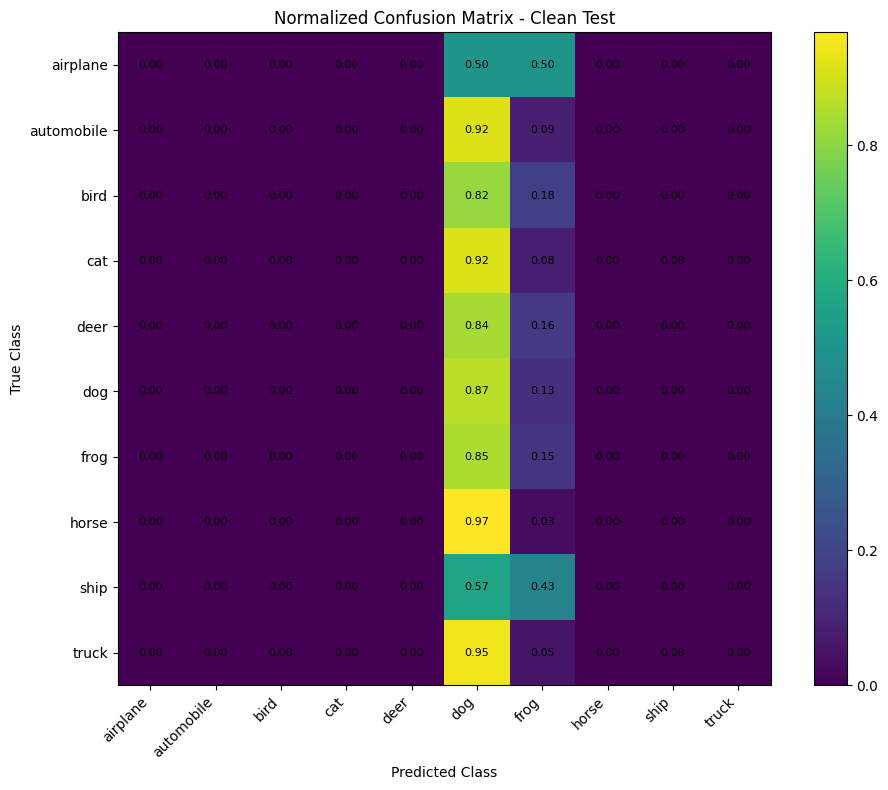

In [47]:
cm = confusion_matrix(y_true, y_pred, normalize="true")

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest")
plt.title("Normalized Confusion Matrix - Clean Test")
plt.colorbar()

plt.xticks(range(10), classes, rotation=45, ha="right")
plt.yticks(range(10), classes)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

for i in range(10):
    for j in range(10):
        plt.text(j, i, f"{cm[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.show()

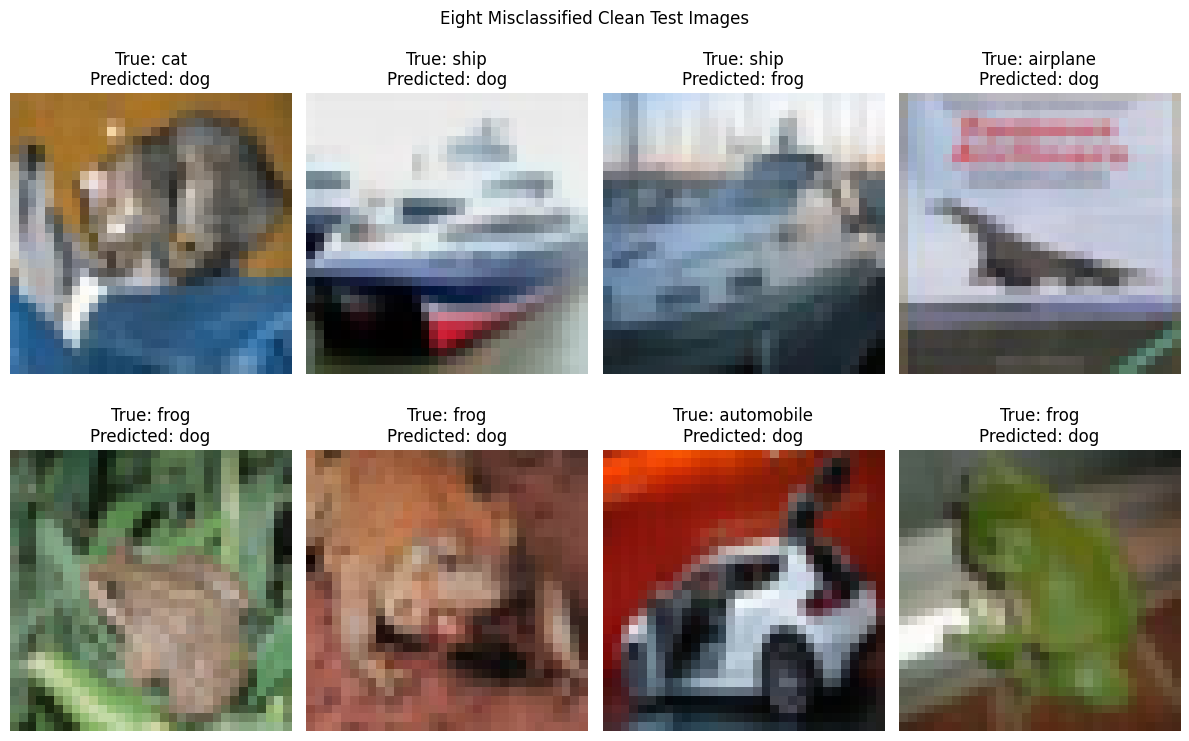

In [48]:
wrong_indices = np.where(y_pred != y_true)[0]
selected_indices = wrong_indices[:8]

plt.figure(figsize=(12, 8))

for plot_id, image_index in enumerate(selected_indices):
    plt.subplot(2, 4, plot_id + 1)
    plt.imshow(X_test[image_index])

    true_label = classes[y_true[image_index]]
    predicted_label = classes[y_pred[image_index]]

    plt.title(f"True: {true_label}\nPredicted: {predicted_label}")
    plt.axis("off")

plt.suptitle("Eight Misclassified Clean Test Images")
plt.tight_layout()
plt.show()

In [49]:
error_rows = []

for image_index in selected_indices:
    error_rows.append({
        "Image Index": int(image_index),
        "True Class": classes[y_true[image_index]],
        "Predicted Class": classes[y_pred[image_index]]
    })

pd.DataFrame(error_rows)

,Image Index,True Class,Predicted Class
0,0,cat,dog
1,1,ship,dog
2,2,ship,frog
3,3,airplane,dog
4,4,frog,dog
5,5,frog,dog
6,6,automobile,dog
7,7,frog,dog


### Analysis of Misclassified Images

The misclassified images help identify the limitations of the trained model. Some images may be incorrectly classified because different classes have similar shapes, colors, or textures. Complex backgrounds, small objects, and unclear object boundaries can also make classification difficult. Since the model was trained on only 400 images, the limited training data may contribute to these errors. The displayed examples show the actual predictions made by the model and help explain its classification failures.

### Hidden Corruption Evaluation and Discussion

The grayscale test experiment evaluates the model's robustness to a visual change that was not explicitly included in the selected augmentation pipeline. The clean-test accuracy is compared with the grayscale-test proxy accuracy to observe the effect of this corruption. If the accuracy decreases, it suggests that the model has difficulty generalizing to this visual change. However, grayscale is used only as a proxy because the actual hidden corruption specified in the assignment was not provided. Therefore, this result should not be reported as the official hidden-corruption test result.

## PART-F

In [51]:
original_predictions = final_model.predict(
    X_test_shifted_proxy, batch_size=32, verbose=1
)

flipped_images = X_test_shifted_proxy[:, :, ::-1, :]

flipped_predictions = final_model.predict(
    flipped_images, batch_size=32, verbose=1
)

tta_predictions = (
    original_predictions + flipped_predictions
) / 2

tta_predicted_classes = np.argmax(tta_predictions, axis=1)

tta_accuracy = np.mean(
    tta_predicted_classes == y_test.flatten()
)

print(f"Shifted Test Accuracy without TTA: "
      f"{shifted_test_accuracy * 100:.2f}%")

print(f"Shifted Test Accuracy with TTA: "
      f"{tta_accuracy * 100:.2f}%")

print(f"Accuracy Change: "
      f"{(tta_accuracy - shifted_test_accuracy) * 100:+.2f} percentage points")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Shifted Test Accuracy without TTA: 10.00%
Shifted Test Accuracy with TTA: 10.45%
Accuracy Change: +0.45 percentage points


In [52]:
normal_predictions = np.argmax(original_predictions, axis=1)
tta_predicted_classes = np.argmax(tta_predictions, axis=1)

normal_accuracy = np.mean(
    normal_predictions == y_test.flatten()
)

tta_accuracy = np.mean(
    tta_predicted_classes == y_test.flatten()
)

print(f"Without TTA: {normal_accuracy * 100:.2f}%")
print(f"With TTA: {tta_accuracy * 100:.2f}%")
print(
    f"Accuracy Change: "
    f"{(tta_accuracy - normal_accuracy) * 100:+.2f} percentage points"
)

Without TTA: 10.45%
With TTA: 10.45%
Accuracy Change: +0.00 percentage points


In [53]:
import time

start_time = time.perf_counter()
final_model.predict(X_test_shifted_proxy, batch_size=32, verbose=0)
normal_time = time.perf_counter() - start_time

start_time = time.perf_counter()

final_model.predict(X_test_shifted_proxy, batch_size=32, verbose=0)
final_model.predict(
    X_test_shifted_proxy[:, :, ::-1, :],
    batch_size=32,
    verbose=0
)

tta_time = time.perf_counter() - start_time

print(f"Without TTA inference time: {normal_time:.2f} seconds")
print(f"With TTA inference time: {tta_time:.2f} seconds")
print(f"Inference cost multiplier: {tta_time / normal_time:.2f}x")

Without TTA inference time: 1.18 seconds
With TTA inference time: 2.33 seconds
Inference cost multiplier: 1.98x


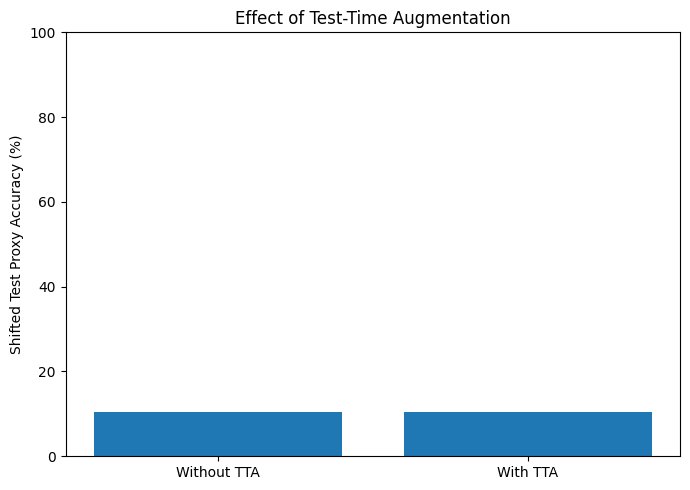

In [54]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Without TTA", "With TTA"],
    [normal_accuracy * 100, tta_accuracy * 100]
)

plt.ylabel("Shifted Test Proxy Accuracy (%)")
plt.title("Effect of Test-Time Augmentation")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

### Part F: Test-Time Augmentation and Inference Cost

Test-Time Augmentation (TTA) improves prediction robustness by averaging the model's softmax predictions for the original image and its horizontally flipped version. The final prediction is selected from the averaged probabilities.

The shifted-test proxy accuracy is compared before and after TTA to measure its effect. TTA may improve accuracy by reducing sensitivity to image orientation, but improvement is not guaranteed. It also increases inference time because the model processes each image twice instead of once.

The experiment reports the measured accuracy change and inference cost multiplier. These results apply to the locally generated shifted-test proxy and should not be treated as results on the official hidden-corruption test set.